OIBSIP – Level 1 Task 4: Sentiment Analysis
Objective: Build a Machine Learning model to classify text into Positive, Negative, and Neutral sentiments.
Dataset: Twitter Sentiment Dataset (TweetEval)
Tools & Technologies:

Python
Pandas
Scikit-learn
NLTK
Matplotlib
Seaborn
WordCloud

Models:

Multinomial Naive Bayes
Logistic Regression
**bold text**

In [1]:
# Install required library
!pip -q install datasets

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset

# Load Twitter Sentiment Dataset
dataset = load_dataset("cardiffnlp/tweet_eval", "sentiment")

# Combine train, validation and test data
df = pd.concat([
    pd.DataFrame(dataset["train"]),
    pd.DataFrame(dataset["validation"]),
    pd.DataFrame(dataset["test"])
], ignore_index=True)

# Rename columns
df = df.rename(columns={
    "text": "Text",
    "label": "Sentiment"
})

# Convert numeric labels into sentiment names
df["Sentiment"] = df["Sentiment"].map({
    0: "Negative",
    1: "Neutral",
    2: "Positive"
})

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

print("\nFirst 5 Records:")
print(df.head())

README.md:   0%|          | 0.00/23.9k [00:00<?, ?B/s]

sentiment/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.78MB            

sentiment/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sentiment/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  901kB            

sentiment/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sentiment/validation-00000-of-00001.parq(…): reconstructing file:   0%|          |  0.00B /  167kB            

sentiment/validation-00000-of-00001.parq(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/45615 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/12284 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Dataset loaded successfully!
Dataset Shape: (59899, 2)

First 5 Records:
                                                Text Sentiment
0  "QT @user In the original draft of the 7th boo...  Positive
1  "Ben Smith / Smith (concussion) remains out of...   Neutral
2  Sorry bout the stream last night I crashed out...   Neutral
3  Chase Headley's RBI double in the 8th inning o...   Neutral
4  @user Alciato: Bee will invest 150 million in ...  Positive


In [2]:
# Dataset information
print("Dataset Information:")
df.info()

# Dataset dimensions
print("\nDataset Shape:", df.shape)

# First 5 records
print("\nFirst 5 Records:")
display(df.head())

# Last 5 records
print("\nLast 5 Records:")
display(df.tail())

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# Sentiment distribution
print("\nSentiment Distribution:")
print(df["Sentiment"].value_counts())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 59899 entries, 0 to 59898
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Text       59899 non-null  object
 1   Sentiment  59899 non-null  object
dtypes: object(2)
memory usage: 936.1+ KB

Dataset Shape: (59899, 2)

First 5 Records:


,Text,Sentiment
0,"""QT @user In the original draft of the 7th boo...",Positive
1,"""Ben Smith / Smith (concussion) remains out of...",Neutral
2,Sorry bout the stream last night I crashed out...,Neutral
3,Chase Headley's RBI double in the 8th inning o...,Neutral
4,@user Alciato: Bee will invest 150 million in ...,Positive



Last 5 Records:


,Text,Sentiment
59894,Sentinel Editorial: FBI’s Comey ‘had no one of...,Neutral
59895,perfect pussy clips #vanessa hudgens zac efron...,Neutral
59896,#latestnews 4 #newmexico #politics + #nativeam...,Neutral
59897,Trying to have a conversation with my dad abou...,Negative
59898,@user You are a stand up guy and a Gentleman V...,Positive



Missing Values:
Text         0
Sentiment    0
dtype: int64

Duplicate Records: 26

Sentiment Distribution:
Sentiment
Neutral     27479
Positive    21043
Negative    11377
Name: count, dtype: int64


In [3]:
# Dataset information
print("Dataset Information:")
df.info()

# Dataset dimensions
print("\nDataset Shape:", df.shape)

# First 5 records
print("\nFirst 5 Records:")
display(df.head())

# Last 5 records
print("\nLast 5 Records:")
display(df.tail())

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# Sentiment distribution
print("\nSentiment Distribution:")
print(df["Sentiment"].value_counts())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 59899 entries, 0 to 59898
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Text       59899 non-null  object
 1   Sentiment  59899 non-null  object
dtypes: object(2)
memory usage: 936.1+ KB

Dataset Shape: (59899, 2)

First 5 Records:


,Text,Sentiment
0,"""QT @user In the original draft of the 7th boo...",Positive
1,"""Ben Smith / Smith (concussion) remains out of...",Neutral
2,Sorry bout the stream last night I crashed out...,Neutral
3,Chase Headley's RBI double in the 8th inning o...,Neutral
4,@user Alciato: Bee will invest 150 million in ...,Positive



Last 5 Records:


,Text,Sentiment
59894,Sentinel Editorial: FBI’s Comey ‘had no one of...,Neutral
59895,perfect pussy clips #vanessa hudgens zac efron...,Neutral
59896,#latestnews 4 #newmexico #politics + #nativeam...,Neutral
59897,Trying to have a conversation with my dad abou...,Negative
59898,@user You are a stand up guy and a Gentleman V...,Positive



Missing Values:
Text         0
Sentiment    0
dtype: int64

Duplicate Records: 26

Sentiment Distribution:
Sentiment
Neutral     27479
Positive    21043
Negative    11377
Name: count, dtype: int64


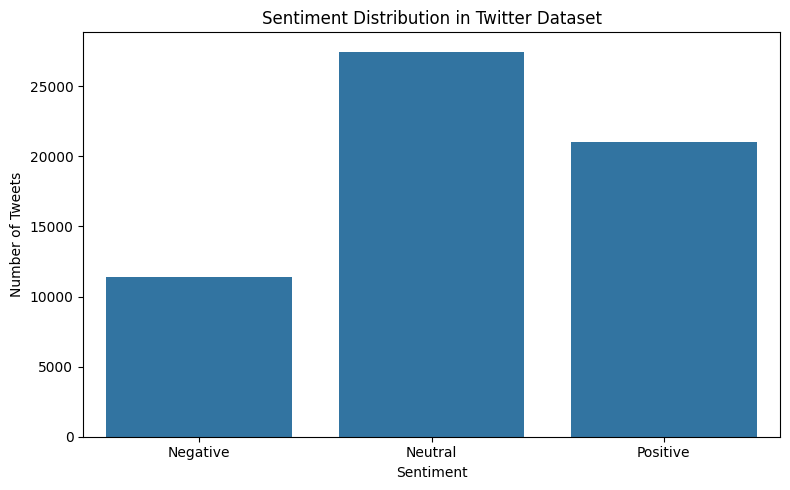

In [4]:
# Sentiment Distribution Bar Chart

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Sentiment",
    order=["Negative", "Neutral", "Positive"]
)

plt.title("Sentiment Distribution in Twitter Dataset")
plt.xlabel("Sentiment")
plt.ylabel("Number of Tweets")
plt.tight_layout()
plt.show()

In [6]:
import re
import nltk
from nltk.corpus import stopwords

# Download English stopwords
nltk.download('stopwords')

# Load stopwords
stop_words = set(stopwords.words('english'))

# Preserve negation words because they affect sentiment
stop_words = stop_words - {'not', 'no', 'nor'}

# Text cleaning function
def clean_text(text):

    # Convert to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r'http\S+|www\S+', '', text)

    # Remove usernames
    text = re.sub(r'@\w+', '', text)

    # Remove hashtag symbol
    text = re.sub(r'#', '', text)

    # Remove punctuation and special characters
    text = re.sub(r'[^a-z\s]', '', text)

    # Tokenization
    words = text.split()

    # Remove stopwords
    words = [word for word in words if word not in stop_words]

    return ' '.join(words)

# Apply preprocessing
df['Cleaned_Text'] = df['Text'].apply(clean_text)

# Compare original and cleaned text
display(df[['Text', 'Cleaned_Text', 'Sentiment']].head())

print("Text preprocessing completed!")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


,Text,Cleaned_Text,Sentiment
0,"""QT @user In the original draft of the 7th boo...",qt original draft th book remus lupin survived...,Positive
1,"""Ben Smith / Smith (concussion) remains out of...",ben smith smith concussion remains lineup thur...,Neutral
2,Sorry bout the stream last night I crashed out...,sorry bout stream last night crashed tonight s...,Neutral
3,Chase Headley's RBI double in the 8th inning o...,chase headleys rbi double th inning david pric...,Neutral
4,@user Alciato: Bee will invest 150 million in ...,alciato bee invest million january another sum...,Positive


Text preprocessing completed!


TF-IDF Vectorization
TF-IDF (Term Frequency–Inverse Document Frequency) is a technique used to convert text into numerical features.

Term Frequency (TF): Measures how frequently a word appears in a document.
Inverse Document Frequency (IDF): Reduces the importance of words that appear frequently across many documents.

TF-IDF helps Machine Learning models identify important words for sentiment classification.


In [7]:
from sklearn.model_selection import train_test_split

# Input and target variables
X = df["Cleaned_Text"]
y = df["Sentiment"]

# Split dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining sentiment distribution:")
print(y_train.value_counts())

print("\nTesting sentiment distribution:")
print(y_test.value_counts())

Training records: 47919
Testing records: 11980

Training sentiment distribution:
Sentiment
Neutral     21983
Positive    16834
Negative     9102
Name: count, dtype: int64

Testing sentiment distribution:
Sentiment
Neutral     5496
Positive    4209
Negative    2275
Name: count, dtype: int64


In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize TF-IDF Vectorizer
tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2)
)

# Fit on training data and transform
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform testing data
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF Vectorization Completed!")

print("Training Feature Shape:", X_train_tfidf.shape)
print("Testing Feature Shape:", X_test_tfidf.shape)

print("\nTotal Features:", len(tfidf.get_feature_names_out()))

TF-IDF Vectorization Completed!
Training Feature Shape: (47919, 10000)
Testing Feature Shape: (11980, 10000)

Total Features: 10000


In [9]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report

# Train Naive Bayes model
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)

# Make predictions
nb_predictions = nb_model.predict(X_test_tfidf)

# Evaluate model
print("Naive Bayes Model Results")
print("Accuracy:", accuracy_score(y_test, nb_predictions))

print("\nClassification Report:")
print(classification_report(y_test, nb_predictions))

Naive Bayes Model Results
Accuracy: 0.632220367278798

Classification Report:
              precision    recall  f1-score   support

    Negative       0.65      0.35      0.45      2275
     Neutral       0.61      0.75      0.67      5496
    Positive       0.67      0.64      0.65      4209

    accuracy                           0.63     11980
   macro avg       0.64      0.58      0.59     11980
weighted avg       0.64      0.63      0.62     11980



In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Create and train model
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train_tfidf, y_train)

# Make predictions
lr_predictions = lr_model.predict(X_test_tfidf)

# Evaluate model
print("Logistic Regression Results")
print("Accuracy:", accuracy_score(y_test, lr_predictions))

print("\nClassification Report:")
print(classification_report(y_test, lr_predictions))

Logistic Regression Results
Accuracy: 0.6593489148580969

Classification Report:
              precision    recall  f1-score   support

    Negative       0.65      0.43      0.52      2275
     Neutral       0.63      0.77      0.69      5496
    Positive       0.71      0.64      0.68      4209

    accuracy                           0.66     11980
   macro avg       0.66      0.61      0.63     11980
weighted avg       0.66      0.66      0.65     11980



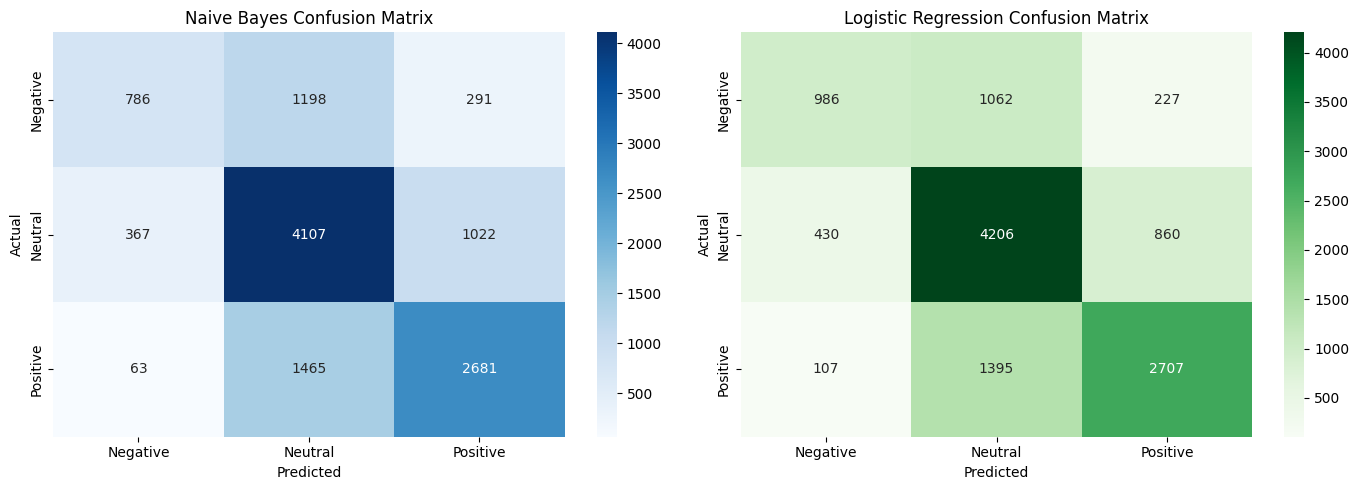

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Naive Bayes Confusion Matrix
nb_cm = confusion_matrix(y_test, nb_predictions)

# Logistic Regression Confusion Matrix
lr_cm = confusion_matrix(y_test, lr_predictions)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(
    nb_cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=nb_model.classes_,
    yticklabels=nb_model.classes_, ax=axes[0]
)
axes[0].set_title("Naive Bayes Confusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(
    lr_cm, annot=True, fmt="d", cmap="Greens",
    xticklabels=lr_model.classes_,
    yticklabels=lr_model.classes_, ax=axes[1]
)
axes[1].set_title("Logistic Regression Confusion Matrix")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [13]:
import pandas as pd

# Create results dataframe
error_df = pd.DataFrame({
    "Text": X_test.values,
    "Actual": y_test.values,
    "Predicted": lr_predictions
})

# Filter incorrect predictions
misclassified = error_df[
    error_df["Actual"] != error_df["Predicted"]
]

# Display 5 examples
print("5 Misclassified Examples:")
display(misclassified.head(5))

5 Misclassified Examples:


,Text,Actual,Predicted
2,captain dubs david wright gives mets back lead...,Positive,Neutral
3,mac n cheetos whopperito year fast food nation...,Neutral,Positive
6,post edited siri vs google voice search may be...,Neutral,Positive
7,rd clumsy funny blonde finish amy schumer jlaw...,Neutral,Positive
13,harvey shawn put no access list along bo carl ...,Negative,Neutral


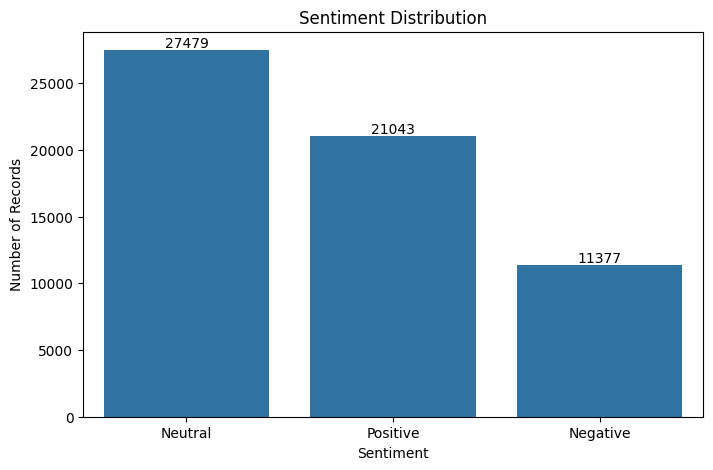

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

sentiment_counts = df["Sentiment"].value_counts()

plt.figure(figsize=(8, 5))
sns.barplot(
    x=sentiment_counts.index,
    y=sentiment_counts.values
)

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Records")

for i, value in enumerate(sentiment_counts.values):
    plt.text(i, value + 200, str(value), ha="center")

plt.show()

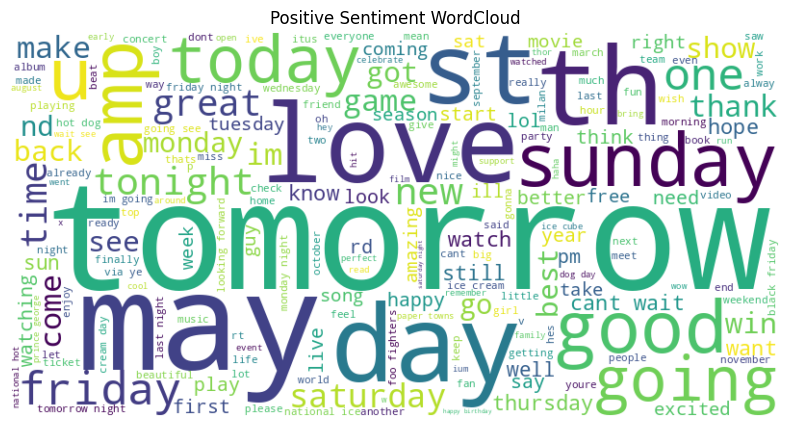

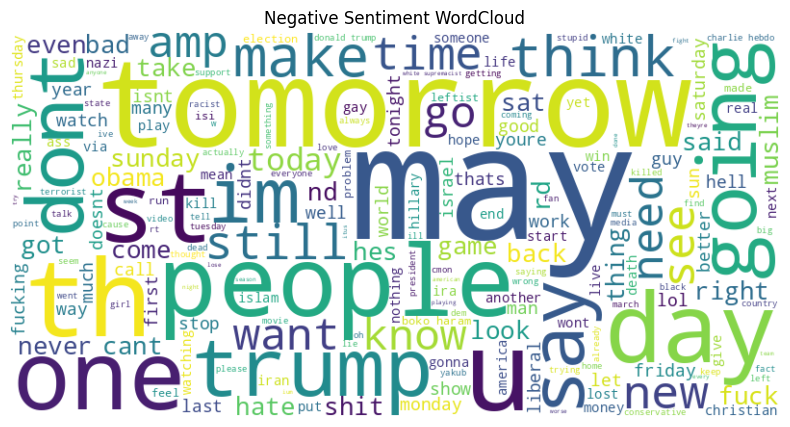

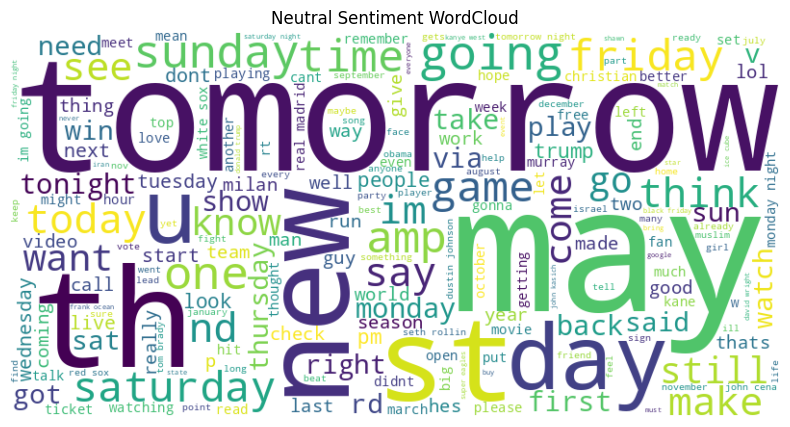

In [16]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

for sentiment in ['Positive', 'Negative', 'Neutral']:
    text = ' '.join(
        df[df['Sentiment'] == sentiment]['Cleaned_Text'].dropna()
    )

    wordcloud = WordCloud(
        width=800,
        height=400,
        background_color='white'
    ).generate(text)

    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.title(f'{sentiment} Sentiment WordCloud')
    plt.show()

TF-IDF Vectorization
TF-IDF stands for Term Frequency–Inverse Document Frequency. It is a technique used in Natural Language Processing (NLP) to convert text into numerical features.

Term Frequency (TF): Measures how often a word appears in a document.
Inverse Document Frequency (IDF): Measures how important a word is across all documents.
Purpose: TF-IDF helps machine learning models understand text by giving higher importance to meaningful words and lower importance to common words.

In this project, TF-IDF converts preprocessed text into numerical features for sentiment classification using Naive Bayes and Logistic Regression.
**bold text**

Conclusion
In this project, sentiment analysis was performed to classify text into Positive, Negative, and Neutral categories using Natural Language Processing and Machine Learning.
Two classification models were evaluated:

Naive Bayes: 63.22% accuracy
Logistic Regression: 65.93% accuracy

Logistic Regression performed better than Naive Bayes on the test dataset.
The analysis shows that Neutral sentiment has the highest number of records, followed by Positive and Negative sentiment.
Real-world Applications:

Analyzing customer reviews and feedback.
Monitoring public opinion on social media.
Understanding customer satisfaction.
Helping businesses improve products and services.

Overall, this project demonstrates how NLP and machine learning can help understand opinions and classify text automatically.
**bold text**